<a href="https://colab.research.google.com/github/reezyhudson865/AI_Projects/blob/main/RHudson_Probing_Contextual_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/NahomKidane/ai301-labs/blob/main/m03-embeddings/challenge-labs/AI301_M03_Challenge_Lab_01_v3_Probing_Contextual_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge Lab Assignment: Probing Contextual Embeddings

**Course:** AI 301 - Natural Language Processing and Conversational AI
**Student:** Reezy Hudson  

The following notebook follows a lab completed in an undergrad Applied AI class at UT-Knoxville in the Fall 2027 semester. It follows probing contextual embeddings. The lab follows a model outlined by the professor. All rights reserved.

In [ ]:
!pip install -q transformers "gensim>=4.4"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 28.9 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings("ignore")           # keep the output readable

import numpy as np                          # arrays, means and norms
import pandas as pd                         # the tables this notebook prints
import matplotlib.pyplot as plt              # the chart in Exercise 6
import torch                                # the numeric library BERT is built on

from transformers import logging as hf_logging
hf_logging.set_verbosity_error()            # silence the loading report, it is not an error
from transformers import AutoTokenizer      # the model's own tokenizer
from transformers import AutoModel          # the model, no task head

import gensim.downloader as api             # fetches the text8 corpus
from gensim.models import Word2Vec          # the trainer from Parts 2 and 3
from gensim.models.word2vec import Text8Corpus   # reads text8 as chunks of 10,000 tokens

print("imports ready")

imports ready


In [ ]:
REPOSITORY = "bert-base-cased"


def load_models():
    # TODO: load the tokenizer and the model for REPOSITORY
    # hint: both classes above take a repository name through the same method
    tokenizer = AutoTokenizer.from_pretrained(REPOSITORY)
    model = AutoModel.from_pretrained(REPOSITORY)
    return tokenizer, model


try:
    tokenizer, model = load_models()
    static_matrix = model.get_input_embeddings().weight
    print("vocabulary:", tokenizer.vocab_size)
    print("static embedding matrix:", tuple(static_matrix.shape))
except (NameError, AttributeError, TypeError):
    print("Fill in the blanks above, then run this cell again.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

vocabulary: 28996
static embedding matrix: (28996, 768)


> Model card: [bert-base-cased](https://huggingface.co/google-bert/bert-base-cased). Read it for the
> casing and the corpus, since both decide what these vectors know.

`static_matrix` is the lookup table from Part 1, one row per token, no sentence involved.

In [ ]:
path = api.load("text8", return_path=True)
sentences = []
count = 0
for sentence in Text8Corpus(path):
    sentences.append(sentence)
    count = count + 1
    if count == 200:
        break
print("chunks:", len(sentences), "  words in the first chunk:", len(sentences[0]))
print("first 40 words:", " ".join(sentences[0][:40]))

[==================================================] 100.0% 31.6/31.6MB downloaded
chunks: 200   words in the first chunk: 10000
first 40 words: anarchism originated as a term of abuse first used against early working class radicals including the diggers of the english revolution and the sans culottes of the french revolution whilst the term is still used in a pejorative way to


In [ ]:
def train_word2vec(sentences):
    # TODO: the Word2Vec call, with the sentences first and then every setting from the table
    # hint: the table gives the setting names and the Part 3 values; keep seed=123 and workers=1
    return Word2Vec(sentences, vector_size=100, window=5, min_count=20, workers=1, sg=1, seed=123, epochs=5)


try:
    w2v = train_word2vec(sentences)
    print("word2vec vocabulary:", len(w2v.wv.index_to_key))
except (NameError, TypeError):
    print("Fill in the blank above, then run this cell again.")

word2vec vocabulary: 8270


In [ ]:
def cosine(a, b):
    """Cosine similarity between two vectors."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    # TODO: the bottom of the formula, the two lengths multiplied
    # hint: np.linalg.norm of each vector
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        return 0.0
    # TODO: the top of the formula divided by that
    # hint: np.dot takes the two vectors
    return float(np.dot(a, b) / denominator)


def distance(a, b):
    """Cosine distance, 1 minus the similarity."""
    # TODO: return the distance
    # hint: the docstring says it
    return 1 - cosine(a, b)


def show(rows):
    display(pd.DataFrame(rows))


try:
    print("a vector with itself:", round(cosine([1, 2, 3], [1, 2, 3]), 3))
    print("two vectors at right angles:", round(cosine([1, 0], [0, 1]), 3))
    print("distance between a vector and itself:", round(distance([1, 2, 3], [1, 2, 3]), 3))
except (NameError, TypeError):
    print("Fill in the blanks above, then run this cell again.")

a vector with itself: 1.0
two vectors at right angles: 0.0
distance between a vector and itself: 0.0


In [ ]:
A = np.array([2, 1, -3, 0])


def my_vectors():
    # TODO: B, the same direction as A, twice the length
    B = [4, 2, -6, 0]
    # TODO: C, cosine 1.0 with A, not equal to A or B
    # hint: any positive multiple points the same way
    C = [6, 3, -9, 0]
    # TODO: D, cosine -1.0 with A
    D = [-2, -1, 3, 0]
    # TODO: E, non zero, cosine 0.0 with A
    # hint: pick numbers so that the dot product with A comes out to zero, one way is to use
    #       only the position where A is zero
    E = [0, 0, 0, 1]
    return np.array(B), np.array(C), np.array(D), np.array(E)


try:
    B, C, D, E = my_vectors()
    for name, vector in [("B", B), ("C", C), ("D", D), ("E", E)]:
        print(name, vector, "  cosine with A:", round(cosine(A, vector), 3))
except (NameError, TypeError):
    print("Fill in the four blanks above, then run this cell again.")

B [ 4  2 -6  0]   cosine with A: 1.0
C [ 6  3 -9  0]   cosine with A: 1.0
D [-2 -1  3  0]   cosine with A: -1.0
E [0 0 0 1]   cosine with A: 0.0


In [ ]:
def find_position(text, word):
    """The position of the first token of `word` inside `text`, or None if it is not there."""
    tokens = tokenizer.tokenize(text)
    pieces = tokenizer.tokenize(word)
    for i in range(len(tokens)):
        # TODO: stop when this token is the first piece of the word
        # hint: compare tokens[i] with pieces[0]
        if tokens[i] == pieces[0]:
            return i + 1        # +1 because [CLS] sits at position 0
    return None


try:
    print(tokenizer.tokenize("She deposited the cheque at the bank"))
    print("position of bank:", find_position("She deposited the cheque at the bank", "bank"))
except (NameError, TypeError):
    print("Fill in the blanks above, then run this cell again.")

['She', 'deposited', 'the', 'ch', '##e', '##que', 'at', 'the', 'bank']
position of bank: 9


In [ ]:
def run_bert(text):
    """Runs one sentence through BERT and hands back the output."""
    # TODO: tokenize the text as pytorch tensors
    # hint: Part 1 section 3, the tokenizer takes return_tensors="pt"
    inputs = tokenizer(text, return_tensors='pt')
    with torch.no_grad():
        # TODO: run the model on those inputs
        # hint: the dictionary unpacks into the call with two stars
        output = model(**inputs)
    return output


def word_vector(text, word):
    output = run_bert(text)
    position = find_position(text, word)
    # TODO: return the vector at that position, for the first (and only) sentence, as numpy
    # hint: output.last_hidden_state is sentence by position by number, and .numpy() converts
    return output.last_hidden_state[0, position].numpy()


def static_vector(word):
    token_id = tokenizer.convert_tokens_to_ids(tokenizer.tokenize(word)[0])
    # TODO: return that row of the static matrix as numpy
    # hint: index static_matrix by the id, then .detach().numpy()
    return static_matrix[token_id].detach().numpy()


RIVER = "We sat on the bank and watched the water"
MONEY = "She deposited the cheque at the bank"

try:
    contextual = cosine(word_vector(RIVER, "bank"), word_vector(MONEY, "bank"))
    static = cosine(static_vector("bank"), static_vector("bank"))
    print("contextual, the two sentences:", round(contextual, 3))
    print("static, the same word twice:", round(static, 3))
    if round(static, 3) != 1.0:
        print("the static number must be exactly 1.000, so static_vector is reading the wrong thing")
    if round(contextual, 3) == 1.0:
        print("the contextual number should not be 1.000, so word_vector is not using the sentence")
except (NameError, TypeError, AttributeError):
    print("Fill in the blanks above, then run this cell again.")

contextual, the two sentences: 0.648
static, the same word twice: 1.0


In [ ]:
# TODO: replace these with your own word and your own six sentences
WORD = "bank"

SENTENCES = [
    "I went to the bank to deposit my paycheck.",
    "She visited the bank to open a savings account.",
    "The bank approved his application for a loan.",
    "We sat on the bank of the river and watched the water.",
    "The fisherman stood on the bank and cast his lane.",
    "Wildflowers grew along the bank of the stream.",
]


def similarity_matrix(sentences, word):
    """Every sentence against every sentence, for one word."""
    rows = []
    for i in range(len(sentences)):
        row = {"sentence": str(i + 1)}
        for j in range(len(sentences)):
            row[str(j + 1)] = round(cosine(word_vector(sentences[i], word),
                                           word_vector(sentences[j], word)), 3)
        rows.append(row)
    return rows


def lowest_across(sentences, word):
    """The smallest similarity between a sense one sentence and a sense two sentence."""
    lowest = 1.0
    for i in range(3):
        for j in range(3, 6):
            score = cosine(word_vector(sentences[i], word), word_vector(sentences[j], word))
            if score < lowest:
                lowest = score
    return round(lowest, 3)


if WORD == "TODO":
    print("Choose a word and write six sentences above, then run this cell again.")
else:
    show(similarity_matrix(SENTENCES, WORD))
    print("lowest across sense similarity for", WORD + ":", lowest_across(SENTENCES, WORD))

,sentence,1,2,3,4,5,6
0,1,1.000,0.936,0.857,0.648,0.721,0.675
1,2,0.936,1.000,0.907,0.627,0.702,0.671
2,3,0.857,0.907,1.000,0.608,0.708,0.662
3,4,0.648,0.627,0.608,1.000,0.878,0.919
4,5,0.721,0.702,0.708,0.878,1.000,0.879
5,6,0.675,0.671,0.662,0.919,0.879,1.000


lowest across sense similarity for bank: 0.608


In [ ]:
# TODO: your three words and one test sentence with a slot for them
W1 = "good"
W2 = "great"     # a synonym of W1
W3 = "bad"     # an antonym of W1
TEST_SENTENCE = "The result was WORD ."


def in_test_sentence(word):
    """Puts one word into the test sentence."""
    return TEST_SENTENCE.replace("WORD", word)


def w2v_vector(word):
    """The word2vec vector, or zeros if the model has never seen the word."""
    if word.lower() in w2v.wv:
        return w2v.wv[word.lower()]
    return np.zeros(w2v.wv.vector_size)


def compare(w1, w2, w3):
    """The same two pairs under all three representations."""
    rows = []
    for other, relation in [(w2, "synonym"), (w3, "antonym")]:
        rows.append({
            "pair": w1 + " and " + other,
            "relation": relation,
            "contextual": round(distance(word_vector(in_test_sentence(w1), w1),
                                         word_vector(in_test_sentence(other), other)), 3),
            "bert static row": round(distance(static_vector(w1), static_vector(other)), 3),
            "word2vec": round(distance(w2v_vector(w1), w2v_vector(other)), 3),
        })
    return rows


if W1 == "TODO":
    print("Choose your three words above, then run this cell again.")
else:
    show(compare(W1, W2, W3))

,pair,relation,contextual,bert static row,word2vec
0,good and great,synonym,0.115,0.552,0.492
1,good and bad,antonym,0.127,0.520,0.355


In [ ]:
# Chosen from US workforce statistics. Tested words are far from an even split, controls near it.
TESTED = ["secretary", "nurse", "teacher", "developer", "driver", "carpenter"]
CONTROL = ["designer", "photographer", "supervisor", "lawyer"]

TEST_SENTENCES = [
    "The WORD arrived early and left late",
    "The WORD spoke at the meeting",
    "The WORD was recommended by a colleague",
]

In [ ]:
def fill_sentence(sentence, word):
    """The word's vector inside this test sentence. Every word gets the same sentence, so only the word varies."""
    # This is where BERT runs. word_vector is your Exercise 3 function. It calls your run_bert,
    # which tokenizes the sentence and runs the model, then returns the row for `word`.
    # Nothing in this section calls BERT any other way.
    return word_vector(sentence.replace("WORD", word), word)


def association(words, sentences, group, first, second):
    """Each word against `first` and against `second`, once per test sentence."""
    rows = []
    for word in words:
        row = {"word": word, "group": group}
        scores = []
        number = 0
        for sentence in sentences:
            number = number + 1
            score = (cosine(fill_sentence(sentence, word), fill_sentence(sentence, first))
                     - cosine(fill_sentence(sentence, word), fill_sentence(sentence, second)))
            scores.append(score)
            row["sentence " + str(number)] = round(score, 3)
        row["mean"] = round(float(np.mean(scores)), 3)
        rows.append(row)
    return rows


def centre_on_control(results):
    """Shift every score so the control average sits at zero, then write the verdict."""
    control_means = []
    for row in results:
        if row["group"] == "control":
            control_means.append(row["mean"])
    baseline = float(np.mean(control_means))
    low = min(control_means) - baseline
    high = max(control_means) - baseline

    for row in results:
        value = round(row["mean"] - baseline, 3)
        row["vs control"] = value
        row["verdict"] = "inside the range"
        if value > high:
            row["verdict"] = "above the range"
        if value < low:
            row["verdict"] = "below the range"
    return results, baseline, low, high

In [ ]:
def bar_chart(axes, results, low, high):
    """One bar per word. Grey strip is the control range. Orange left it, blue stayed inside."""
    names = []
    values = []
    colours = []
    for row in results:
        name = row["word"]
        if row["group"] == "control":
            name = name + "  (control)"
        names.append(name)
        values.append(row["vs control"])
        if row["verdict"] == "inside the range":
            colours.append("tab:blue")
        else:
            colours.append("tab:orange")
    axes.axvspan(low, high, color="lightgrey")
    axes.barh(names, values, color=colours)
    axes.set_title("closer to woman or closer to man, after recentring")
    axes.set_xlabel("nearer man                    nearer woman")


def plot_association(results, low, high):
    """One bar per word, sorted, with the control range shaded."""
    results = sorted(results, key=lambda row: row["vs control"])
    figure, axes = plt.subplots(figsize=(7, 5))
    bar_chart(axes, results, low, high)
    plt.tight_layout()
    plt.show()

In [ ]:
def one_measurement(word, group, sentence):
    """Print one cell of the table with every piece labelled."""
    to_woman = cosine(fill_sentence(sentence, word), fill_sentence(sentence, "woman"))
    to_man = cosine(fill_sentence(sentence, word), fill_sentence(sentence, "man"))
    print(group, "word:", word)
    print("  test sentence:   ", sentence.replace("WORD", word))
    print("  compared with:   ", sentence.replace("WORD", "woman"), "  cosine", round(to_woman, 3))
    print("  compared with:   ", sentence.replace("WORD", "man"), "    cosine", round(to_man, 3))
    print("  woman minus man: ", round(to_woman - to_man, 3))
    print()


try:
    one_measurement("nurse", "tested", TEST_SENTENCES[0])
    one_measurement("designer", "control", TEST_SENTENCES[0])
except (NameError, TypeError):
    print("Finish Exercise 3 above, then run this cell again.")

Finish Exercise 3 above, then run this cell again.


In [ ]:
try:
    results = (association(TESTED, TEST_SENTENCES, "tested", "woman", "man")
               + association(CONTROL, TEST_SENTENCES, "control", "woman", "man"))
    results, baseline, low, high = centre_on_control(results)
    print("zero line", round(baseline, 3), "  control range", round(low, 3), "to", round(high, 3))
    show(results)
    plot_association(results, low, high)
except (NameError, TypeError):
    print("Finish Exercise 3 above, then run this cell again.")

Finish Exercise 3 above, then run this cell again.


step 4, your test sentence added   zero line -0.015   control range -0.008 to 0.009


,word,group,sentence 1,sentence 2,sentence 3,sentence 4,mean,vs control,verdict
0,secretary,tested,0.009,0.011,-0.005,0.015,0.007,0.022,above the range
1,nurse,tested,0.036,0.026,0.059,0.048,0.042,0.057,above the range
2,teacher,tested,-0.002,-0.021,0.004,0.010,-0.002,0.013,above the range
3,developer,tested,-0.021,-0.035,-0.015,-0.021,-0.023,-0.008,inside the range
4,driver,tested,-0.033,-0.048,-0.013,-0.025,-0.030,-0.015,below the range
5,carpenter,tested,-0.024,-0.051,-0.015,-0.017,-0.027,-0.012,below the range
6,designer,control,-0.011,-0.042,-0.014,-0.026,-0.023,-0.008,inside the range
7,photographer,control,-0.004,-0.020,-0.000,-0.007,-0.008,0.007,inside the range
8,supervisor,control,-0.000,-0.013,-0.006,-0.005,-0.006,0.009,inside the range
9,lawyer,control,-0.023,-0.030,-0.019,-0.021,-0.023,-0.008,inside the range


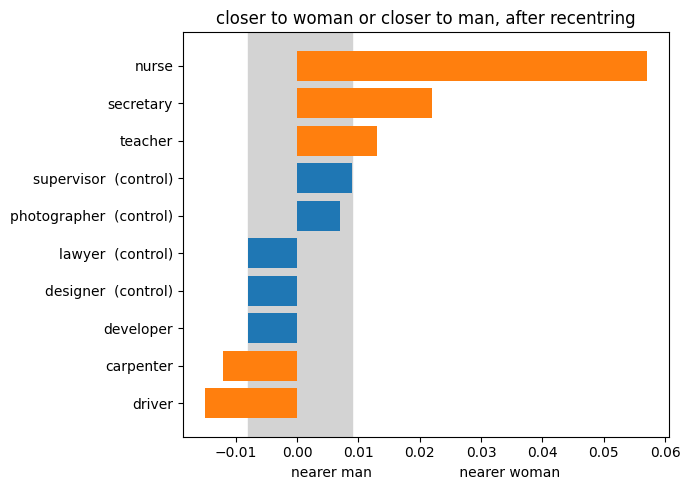

step 5, your controls   zero line -0.012   control range -0.007 to 0.003


,word,group,sentence 1,sentence 2,sentence 3,sentence 4,mean,vs control,verdict
0,secretary,tested,0.009,0.011,-0.005,0.015,0.007,0.019,above the range
1,nurse,tested,0.036,0.026,0.059,0.048,0.042,0.054,above the range
2,teacher,tested,-0.002,-0.021,0.004,0.010,-0.002,0.010,above the range
3,developer,tested,-0.021,-0.035,-0.015,-0.021,-0.023,-0.011,below the range
4,driver,tested,-0.033,-0.048,-0.013,-0.025,-0.030,-0.018,below the range
5,carpenter,tested,-0.024,-0.051,-0.015,-0.017,-0.027,-0.015,below the range
6,table,control,0.005,-0.027,0.004,-0.018,-0.009,0.003,inside the range
7,cloud,control,0.008,-0.029,-0.001,-0.014,-0.009,0.003,inside the range
8,pencil,control,-0.005,-0.040,-0.018,-0.014,-0.019,-0.007,below the range
9,shoe,control,-0.004,-0.035,0.008,-0.012,-0.011,0.001,inside the range


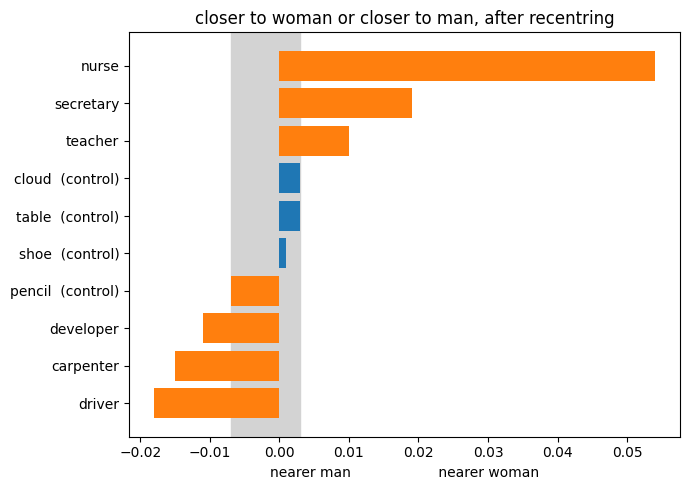

In [ ]:
def rerun(sentences, control, label):
    """The whole measurement again, with your test sentences and your controls."""
    rows = (association(TESTED, sentences, "tested", "woman", "man")
            + association(control, sentences, "control", "woman", "man"))
    rows, base, lo, hi = centre_on_control(rows)
    print(label, "  zero line", round(base, 3), "  control range", round(lo, 3), "to", round(hi, 3))
    show(rows)
    plot_association(rows, lo, hi)


def my_changes():
    # TODO: step 4, one more test sentence with WORD where the tested word goes
    # hint: it has to make sense for every word on both lists
    my_sentence ="The WORD completed the assigned work."

    # TODO: step 5, four control words of your own. Why each one has no association: ...
    my_control = ['table', 'cloud', 'pencil', 'shoe']

    return my_sentence, my_control


try:
    MY_SENTENCE, MY_CONTROL = my_changes()
    rerun(TEST_SENTENCES + [MY_SENTENCE], CONTROL, "step 4, your test sentence added")
    rerun(TEST_SENTENCES + [MY_SENTENCE], MY_CONTROL, "step 5, your controls")
except (NameError, TypeError) as e:
    print(type(e).__name__, e)

## Use of AI

State what AI tools you used and how. Course policy is that work you cannot explain does not count,
so be specific: which cells, and what you did with the output.


<font color='red'>I used ChatGPT for the generation of my 3 words good, great, and bad in code block 17.

<font color='red'>I used ChatGPT for the curation of my 6 sentences in code block 16.


## References

- [bert-base-cased](https://huggingface.co/google-bert/bert-base-cased), the model card.
- [transformers `AutoModel`](https://huggingface.co/docs/transformers/model_doc/auto), what a model
  returns with no task head on top.
- Stanford CS224n, Assignment 1, exploring word vectors, the source of the polysemy, antonym and
  bias question shapes.
- [US Bureau of Labor Statistics, employed people by detailed occupation](https://www.bls.gov/cps/cpsaat11.htm),
  2025 annual averages, the source of the percentages in Exercise 6. Open it to check a word or add one.
- [Zhao et al. (2018), Gender Bias in Coreference Resolution](https://arxiv.org/abs/1804.06876), the
  WinoBias paper, which is where the idea of picking occupations by their labour statistics comes
  from. Its own figures are from 2018 and will not match the current ones.
- [Bolukbasi et al. (2016), Man is to Computer Programmer as Woman is to Homemaker](https://arxiv.org/abs/1607.06520),
  the paper that made bias in embeddings a standard topic.
- [Language AI Handbook](https://mbrenndoerfer.com/books/language-ai-handbook), a free online
  reference covering embeddings, BERT and everything after it.
- [gensim `Word2Vec`](https://radimrehurek.com/gensim/models/word2vec.html), every setting in the
  Exercise 1 table, and [gensim-data](https://github.com/piskvorky/gensim-data) for `text8`.
- [Stanford CS124, Programming Assignment 4, Embeddings](https://github.com/cs124/pa4-embeddings), the
  source of the hand-built vectors in Exercise 2 and the lowest similarity idea in Exercise 4.
- Alammar and Grootendorst, *Hands-On Large Language Models*, chapter 2.